# IKEA Global Pricing Strategy — Business Analytics Project (MBI806B)

**Business problem:** IKEA sells the same products across dozens of national markets, but prices
are set locally. This notebook builds a model that predicts a product's price from its
attributes (category, type, size, customer rating, popularity badge) within a single currency
zone, so we can identify which product attributes actually drive price and flag products whose
price looks out of line with similar items — supporting a more consistent, defensible global
pricing strategy.

**Target variable:** `price` (EUR, restricted to the Eurozone subset of the catalog — see
scoping decision below).

**Models compared:** Linear Regression (baseline/interpretability), Random Forest, XGBoost.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 140)
sns.set_style('whitegrid')

RANDOM_STATE = 42


## 2. Load the raw data

Uses Colab's file upload widget — run this cell, then choose `IKEA_product_catalog.csv` from
your computer when the picker appears.

In [ ]:
# Data: download IKEA_product_catalog.csv from Kaggle (see data/README.md).
# In Google Colab this cell asks you to upload it; locally, put it next to this notebook.
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    pass

df_raw = pd.read_csv('IKEA_product_catalog.csv', low_memory=False)
print('Shape:', df_raw.shape)
df_raw.head()

## 3. Initial inspection

Check dtypes, true vs. placeholder missingness, and duplicates before deciding on cleaning steps.

In [3]:
print(df_raw.dtypes)
print()
print('True nulls per column:')
print(df_raw.isnull().sum())


unique_id                   str
product_id                int64
product_name                str
product_type                str
product_measurements        str
product_description         str
main_category               str
sub_category                str
product_rating              str
product_rating_count        str
badge                       str
online_sellable            bool
url                         str
price                   float64
currency                    str
discount                    str
sale_tag                    str
country                     str
dtype: object

True nulls per column:
unique_id               0
product_id              0
product_name            0
product_type            0
product_measurements    0
product_description     0
main_category           0
sub_category            0
product_rating          0
product_rating_count    0
badge                   0
online_sellable         0
url                     0
price                   0
currency              

In [4]:
# The catalog uses string placeholders ('none' / 'NONE') instead of real NaNs
# in several columns — check how common that is before treating them as missing.
for c in ['product_rating', 'product_rating_count', 'badge', 'discount', 'sale_tag']:
    placeholder = df_raw[c].astype(str).str.lower().eq('none').sum()
    print(f'{c:22s} placeholder-"none" count: {placeholder:>7,}  ({placeholder/len(df_raw):.1%})')


product_rating         placeholder-"none" count: 131,960  (32.9%)
product_rating_count   placeholder-"none" count: 131,960  (32.9%)
badge                  placeholder-"none" count: 372,043  (92.8%)
discount               placeholder-"none" count: 400,918  (100.0%)


sale_tag               placeholder-"none" count: 330,134  (82.3%)


In [5]:
print('Duplicate rows (exact):', df_raw.duplicated().sum())
print('Unique product_id:', df_raw['product_id'].nunique(), ' — one product sold in multiple countries, so this is expected to be << row count')
print('Rows per country (top 10):')
print(df_raw['country'].value_counts().head(10))


Duplicate rows (exact): 0
Unique product_id: 34932  — one product sold in multiple countries, so this is expected to be << row count
Rows per country (top 10):
country
Sweden         10722
Germany        10300
Italy          10216
Netherlands    10130
UK             10052
USA             9953
France          9895
Austria         9877
Norway          9845
Spain           9789
Name: count, dtype: int64


## 4. Scoping decisions

Two structural problems have to be solved before modelling `price` makes sense:

1. **34 currencies.** Comparing raw prices across currencies without converting them would mix
   apples and oranges — a price difference could just be a stronger/weaker currency, not a real
   pricing decision. Rather than pull in external, time-sensitive FX rates (which adds another
   source of error and dates the analysis), this project scopes the price model to the
   **Eurozone subset** (`currency == 'EUR'`), which is still ~124k rows across ~17 countries —
   large enough for a robust model while keeping every price directly comparable.
2. **Category labels are localised, not translated consistently.** The same `product_id` can
   carry a different `main_category` string in every market (confirmed below: ~65% of products
   have more than one distinct label across countries) — sometimes just a language difference,
   sometimes a different local classification. Using the raw `main_category` column as a model
   feature would treat the same product as several different categories. This project instead
   builds an **English-language reference category** per product by joining each product to its
   `main_category`/`product_type` from whichever English-speaking market carries it, in priority
   order UK → USA → Australia → Canada → Ireland.

In [6]:
# Confirm the category-localisation problem before fixing it
dup_main = df_raw.groupby('product_id')['main_category'].nunique()
dup_type = df_raw.groupby('product_id')['product_type'].nunique()
print(f"Products with >1 distinct main_category label across countries: {(dup_main>1).sum():,} of {len(dup_main):,} ({(dup_main>1).mean():.1%})")
print(f"Products with >1 distinct product_type label across countries:  {(dup_type>1).sum():,} of {len(dup_type):,} ({(dup_type>1).mean():.1%})")


Products with >1 distinct main_category label across countries: 22,806 of 34,932 (65.3%)
Products with >1 distinct product_type label across countries:  20,208 of 34,932 (57.8%)


In [7]:
# Build the English-reference category map (one row per product_id)
ENGLISH_MARKETS_PRIORITY = ['UK', 'USA', 'Australia', 'Canada', 'Ireland']

ref = df_raw[df_raw['country'].isin(ENGLISH_MARKETS_PRIORITY)].copy()
ref['market_priority'] = ref['country'].map({c: i for i, c in enumerate(ENGLISH_MARKETS_PRIORITY)})
ref = ref.sort_values('market_priority').drop_duplicates('product_id', keep='first')

category_map = ref.set_index('product_id')[['main_category', 'product_type']]
category_map.columns = ['main_category_en', 'product_type_en']

coverage = len(category_map) / df_raw['product_id'].nunique()
print(f'English category reference built from {len(category_map):,} products ({coverage:.1%} of all {df_raw["product_id"].nunique():,} unique products)')
print(f'Distinct canonical main_category_en values: {category_map["main_category_en"].nunique()}  (down from {df_raw["main_category"].nunique()} raw localised values)')


English category reference built from 18,523 products (53.0% of all 34,932 unique products)


Distinct canonical main_category_en values: 51  (down from 314 raw localised values)


In [8]:
# Scope to the Eurozone subset and attach the English category reference
df_eur = df_raw[df_raw['currency'] == 'EUR'].copy()
df_eur = df_eur.join(category_map, on='product_id')

before = len(df_eur)
df_eur = df_eur.dropna(subset=['main_category_en'])
after = len(df_eur)
print(f'EUR rows: {before:,} -> {after:,} after dropping products with no English-market category reference ({(before-after)/before:.1%} dropped)')
print()
print('Eurozone countries represented:', sorted(df_eur["country"].unique()))


EUR rows: 124,436 -> 105,671 after dropping products with no English-market category reference (15.1% dropped)

Eurozone countries represented: ['Austria', 'Belgium', 'Croatia', 'Finland', 'France', 'Germany', 'Ireland', 'Italy', 'Netherlands', 'Portugal', 'Slovakia', 'Slovenia', 'Spain']


## 5. Consolidate the category taxonomy

The English reference still leaves ~50 category labels because UK/USA/Australia/Canada/Ireland
each spell things slightly differently (`storage-organisation` vs `storage-organization`) or
split things at a different level (`home-storage-organisers` vs `storage-furniture`). For
modelling, high-cardinality categoricals hurt more than they help, so this keeps the **top 15
categories by frequency** and buckets everything else into `Other` — a standard, defensible way
to control cardinality while keeping the categories that actually have enough data to learn a
price relationship from.

In [9]:
TOP_N_CATEGORIES = 15
top_categories = df_eur['main_category_en'].value_counts().nlargest(TOP_N_CATEGORIES).index
df_eur['category_grouped'] = df_eur['main_category_en'].where(
    df_eur['main_category_en'].isin(top_categories), other='Other'
)
print(df_eur['category_grouped'].value_counts())


category_grouped
storage-furniture             21945
Other                         13427
kitchenware-tableware          8593
decoration                     8565
kitchens                       8116
home-storage-organisers        7443
tables-chairs                  6906
beds-mattresses                6330
lighting                       5573
textiles                       3193
outdoor-living                 3096
storage-organization           2778
living-room-seating            2705
baby-children                  2401
office-furniture               2395
bathroom-furniture-storage     2205
Name: count, dtype: int64


## 6. Parse `product_measurements` into usable numeric features

The raw field mixes several units in one free-text string (`'100x45 cm'`, `'27 cm'`, `'425 g'`,
`'1/0.4 l'`, `'none'`), and some entries carry adjustable/extendable sizes as slash-separated
alternatives (`'48/104/159x85 cm'` — a table that extends across three lengths). The parser below:

- takes the unit as whatever word trails the number(s) (`cm`, `g`, `l`, …) — most items are `cm`;
- for adjustable dimensions, averages the slash-separated alternatives into one representative
  number per axis (a documented simplification — the alternative would be one row per size option);
- ignores any imperial conversion shown in parentheses, since it duplicates the metric figure;
- computes `size_cm3` (an approximate bounding-box volume) only when the unit is `cm` and at
  least two axes were found — single-axis `cm` entries (e.g. a diameter) don't imply a volume.

In [10]:
import re

def parse_measurement(text):
    """Parse one product_measurements string into unit / dimension-count / size proxy."""
    if not isinstance(text, str) or text.strip().lower() == 'none':
        return pd.Series({'measure_unit': 'missing', 'n_dims': 0, 'size_cm3': np.nan})

    main_part = text.strip().split('(')[0].strip()  # drop any imperial conversion in parentheses
    m_unit = re.search(r'([a-zA-Z]+)\s*$', main_part)
    unit = m_unit.group(1).lower() if m_unit else 'unknown'

    num_part = re.sub(r'[a-zA-Z]+\s*$', '', main_part).strip()  # strip trailing unit, keep 'x'
    dims = []
    for axis in num_part.split('x'):
        vals = [float(v) for v in re.findall(r'\d+\.?\d*', axis)]
        if vals:
            dims.append(sum(vals) / len(vals))  # average adjustable-size alternatives

    size_cm3 = np.nan
    if unit == 'cm' and len(dims) >= 2:
        size_cm3 = float(np.prod(dims))

    return pd.Series({'measure_unit': unit, 'n_dims': len(dims), 'size_cm3': size_cm3})

measure_features = df_eur['product_measurements'].apply(parse_measurement)
df_eur = pd.concat([df_eur, measure_features], axis=1)

print(df_eur['measure_unit'].value_counts())
print()
print('size_cm3 available for', df_eur['size_cm3'].notna().sum(), f"of {len(df_eur):,} rows ({df_eur['size_cm3'].notna().mean():.1%})")
df_eur[['product_measurements', 'measure_unit', 'n_dims', 'size_cm3']].sample(8, random_state=1)


measure_unit
cm         70915
missing    25492
l           2908
cl          1373
mm          1226
g           1057
m            643
hr           535
ml           437
unknown      208
h            100
pack          91
xl            76
double        70
mah           63
w             54
single        53
kg            53
king          48
months        34
ur            31
v             26
k             26
pieces        23
s             19
kom           14
lm            13
ces           12
kelvin        12
ks            11
kos           11
medium         8
mjeseci        4
mesi           4
mesecev        4
pezzi          3
kusov          3
kosi           3
large          2
mois           2
veliko         1
moyen          1
medio          1
srednje        1
Name: count, dtype: int64

size_cm3 available for 54425 of 105,671 rows (51.5%)


,product_measurements,measure_unit,n_dims,size_cm3
119675,198x35x212 cm,cm,3,1469160.0
331845,70x35x70 cm,cm,3,171500.0
125754,80x20 cm,cm,2,1600.0
129076,none,missing,0,NaN
342395,none,missing,0,NaN
315667,65x65 cm,cm,2,4225.0
97789,none,missing,0,NaN
101442,150x300 cm,cm,2,45000.0


## 7. Handle the `'none'` placeholders and the near-empty `discount` column

`product_rating` / `product_rating_count` are genuinely missing for ~33% of rows (no reviews
yet) — kept as real `NaN` so models and summary stats don't silently treat "no rating" as a
rating of zero. `badge` and `sale_tag` are mostly `'none'`/`'NONE'` by design (most products
carry no badge) — that's a legitimate category, not missing data, so it's kept as an explicit
`'NONE'` level. `discount` is dropped outright: **99.97% of rows are `'none'`**, so it carries
almost no information for a general price model.

In [11]:
# Convert genuine 'no rating yet' placeholders to real NaN
df_eur['product_rating'] = pd.to_numeric(df_eur['product_rating'].replace('none', np.nan), errors='coerce')
df_eur['product_rating_count'] = pd.to_numeric(df_eur['product_rating_count'].replace('none', np.nan), errors='coerce')
df_eur['has_rating'] = df_eur['product_rating'].notna()

# badge / sale_tag: 'none' is a real category (no badge), not missing data — just standardise casing
df_eur['badge'] = df_eur['badge'].str.upper()
df_eur['sale_tag'] = df_eur['sale_tag'].str.upper()

# discount: 99.97% 'none' — not usable as a feature, drop it
print('discount dropped: non-"none" share was', f"{(df_raw['discount'].str.lower() != 'none').mean():.3%}")
df_eur = df_eur.drop(columns=['discount'])

print(df_eur[['product_rating', 'has_rating', 'badge', 'sale_tag']].describe(include='all').T)


discount dropped: non-"none" share was 0.032%


                  count unique   top   freq      mean       std  min  25%  50%  75%  max
product_rating  80374.0    NaN   NaN    NaN  4.410836  0.618575  1.0  4.2  4.6  4.8  5.0
has_rating       105671      2  True  80374       NaN       NaN  NaN  NaN  NaN  NaN  NaN
badge            105671      3  NONE  98022       NaN       NaN  NaN  NaN  NaN  NaN  NaN
sale_tag         105671      6  NONE  89680       NaN       NaN  NaN  NaN  NaN  NaN  NaN


## 8. Final cleaned dataset

In [12]:
model_cols = ['unique_id', 'product_id', 'product_name', 'category_grouped', 'product_type_en',
              'price', 'country', 'measure_unit', 'n_dims', 'size_cm3',
              'product_rating', 'has_rating', 'product_rating_count',
              'badge', 'sale_tag', 'online_sellable']
df_clean = df_eur[model_cols].reset_index(drop=True)

print('Cleaned dataset shape:', df_clean.shape)
print()
print(df_clean.isna().sum())
print()
df_clean.head()


Cleaned dataset shape: (105671, 16)

unique_id                   0
product_id                  0
product_name                0
category_grouped            0
product_type_en             0
price                       0
country                     0
measure_unit                0
n_dims                      0
size_cm3                51246
product_rating          25297
has_rating                  0
product_rating_count    25297
badge                       0
sale_tag                    0
online_sellable             0
dtype: int64



,unique_id,product_id,product_name,category_grouped,product_type_en,price,country,measure_unit,n_dims,size_cm3,product_rating,has_rating,product_rating_count,badge,sale_tag,online_sellable
0,10018194-Austria,10018194,ORDNING,kitchenware-tableware,Dish drainer,27.99,Austria,cm,3,48600.0,3.3,True,6.0,NONE,NONE,True
1,10018194-Belgium,10018194,ORDNING,kitchenware-tableware,Dish drainer,29.99,Belgium,cm,3,48600.0,3.7,True,543.0,NONE,NONE,True
2,10018194-Croatia,10018194,ORDNING,kitchenware-tableware,Dish drainer,19.99,Croatia,cm,3,48600.0,3.7,True,543.0,NONE,NONE,True
3,10018194-Finland,10018194,ORDNING,kitchenware-tableware,Dish drainer,29.99,Finland,cm,3,48600.0,3.7,True,543.0,NONE,NONE,True
4,10018194-France,10018194,ORDNING,kitchenware-tableware,Dish drainer,35.00,France,cm,3,48600.0,4.0,True,158.0,NONE,NONE,True


In [13]:
df_clean.to_csv('ikea_eur_cleaned.csv', index=False)
print('Saved ikea_eur_cleaned.csv —', df_clean.shape)


Saved ikea_eur_cleaned.csv — (105671, 16)


## 9. Exploratory Data Analysis

Before modelling, this section checks: how `price` is distributed (which decides whether to
model it directly or transform it), whether price differs meaningfully by category and by
country (the core business question — is IKEA's Eurozone pricing consistent, or are there
attribute- and market-driven patterns worth understanding), and how the engineered numeric
features (`size_cm3`, `product_rating`) relate to price.

In [14]:
# Chart styling — a small, fixed set of colours used consistently across every figure in this
# notebook (never re-assigned chart-to-chart), matching the categorical/sequential/diverging
# roles a colour is actually playing rather than picking colours ad hoc.
CAT_COLORS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
INK_PRIMARY, INK_SECONDARY, INK_MUTED = '#0b0b0b', '#52514e', '#898781'
GRIDLINE, BASELINE, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE,
    'axes.edgecolor': BASELINE, 'axes.labelcolor': INK_SECONDARY,
    'text.color': INK_PRIMARY, 'xtick.color': INK_MUTED, 'ytick.color': INK_MUTED,
    'axes.grid': True, 'grid.color': GRIDLINE, 'grid.linewidth': 0.8,
    'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 11,
})

def style_ax(ax, title):
    ax.set_title(title, color=INK_PRIMARY, fontsize=13, fontweight='bold', loc='left', pad=12)
    ax.grid(axis='y' if ax.get_xlabel()=='' else 'x', alpha=0.6)


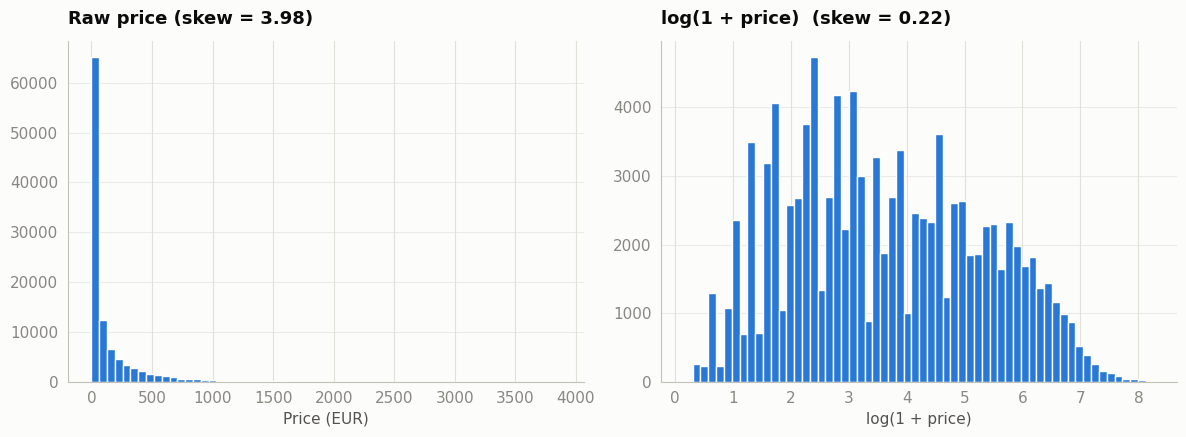

In [15]:
# Price distribution: raw vs. log1p — decides the modelling target
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(df_clean['price'], bins=60, color=CAT_COLORS[0])
style_ax(axes[0], f"Raw price (skew = {df_clean['price'].skew():.2f})")
axes[0].set_xlabel('Price (EUR)')

log_price = np.log1p(df_clean['price'])
axes[1].hist(log_price, bins=60, color=CAT_COLORS[0])
style_ax(axes[1], f"log(1 + price)  (skew = {log_price.skew():.2f})")
axes[1].set_xlabel('log(1 + price)')

plt.tight_layout()
plt.savefig('fig1_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


Raw price is heavily right-skewed (a small number of expensive wardrobes/sofas stretch the
tail) — a standard problem for linear models, which assume roughly symmetric, homoscedastic
residuals. `log1p(price)` is close to symmetric, so **the model target for all three algorithms
below is `log1p(price)`**, with predictions converted back with `expm1()` before computing
error metrics — that keeps the reported RMSE/MAE in real, interpretable euros rather than
log-euros.

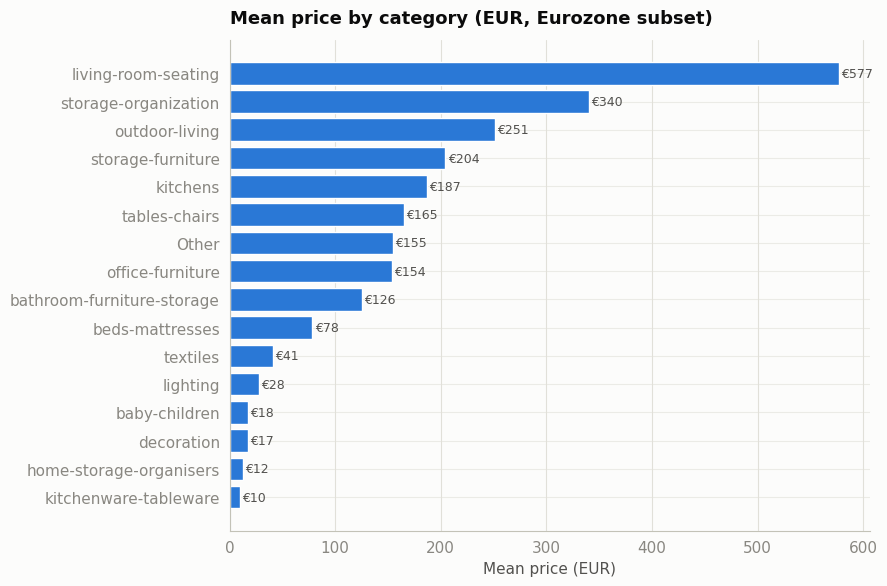

In [16]:
# Mean price by category — the main business-facing comparison
cat_price = df_clean.groupby('category_grouped')['price'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(cat_price.index[::-1], cat_price.values[::-1], color=CAT_COLORS[0])
style_ax(ax, 'Mean price by category (EUR, Eurozone subset)')
ax.set_xlabel('Mean price (EUR)')
for bar, val in zip(bars, cat_price.values[::-1]):
    ax.text(val + 2, bar.get_y() + bar.get_height()/2, f'€{val:,.0f}', va='center', color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.savefig('fig2_price_by_category.png', dpi=150, bbox_inches='tight')
plt.show()


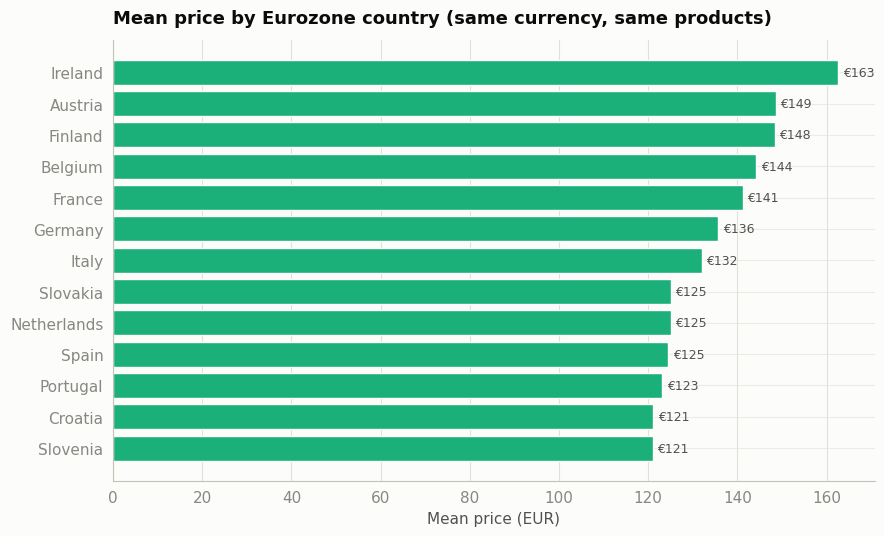

Range: €121.04 (Slovenia) to €162.65 (Ireland)
Coefficient of variation across country means: 9.8%


In [17]:
# Mean price by country — checks whether Eurozone pricing is consistent across markets
country_price = df_clean.groupby('country')['price'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(country_price.index[::-1], country_price.values[::-1], color=CAT_COLORS[2])
style_ax(ax, 'Mean price by Eurozone country (same currency, same products)')
ax.set_xlabel('Mean price (EUR)')
for bar, val in zip(bars, country_price.values[::-1]):
    ax.text(val + 1, bar.get_y() + bar.get_height()/2, f'€{val:,.0f}', va='center', color=INK_SECONDARY, fontsize=9)
plt.tight_layout()
plt.savefig('fig3_price_by_country.png', dpi=150, bbox_inches='tight')
plt.show()

print('Range:', f"€{country_price.min():.2f} ({country_price.idxmin()}) to €{country_price.max():.2f} ({country_price.idxmax()})")
print('Coefficient of variation across country means:', f"{country_price.std()/country_price.mean():.1%}")


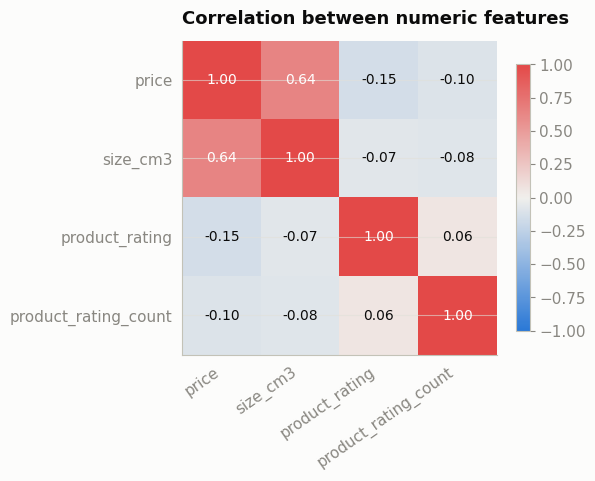

In [18]:
# Correlation among numeric features — diverging colour (blue=negative, red=positive, grey=0)
from matplotlib.colors import LinearSegmentedColormap
diverging_cmap = LinearSegmentedColormap.from_list('diverging', ['#2a78d6', '#f0efec', '#e34948'])

num_cols = ['price', 'size_cm3', 'product_rating', 'product_rating_count']
corr = df_clean[num_cols].corr()

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap=diverging_cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(num_cols))); ax.set_xticklabels(num_cols, rotation=35, ha='right')
ax.set_yticks(range(len(num_cols))); ax.set_yticklabels(num_cols)
ax.grid(False)
for i in range(len(num_cols)):
    for j in range(len(num_cols)):
        ax.text(j, i, f'{corr.iloc[i,j]:.2f}', ha='center', va='center',
                 color='white' if abs(corr.iloc[i,j]) > 0.5 else INK_PRIMARY, fontsize=10)
style_ax(ax, 'Correlation between numeric features')
plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout()
plt.savefig('fig4_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


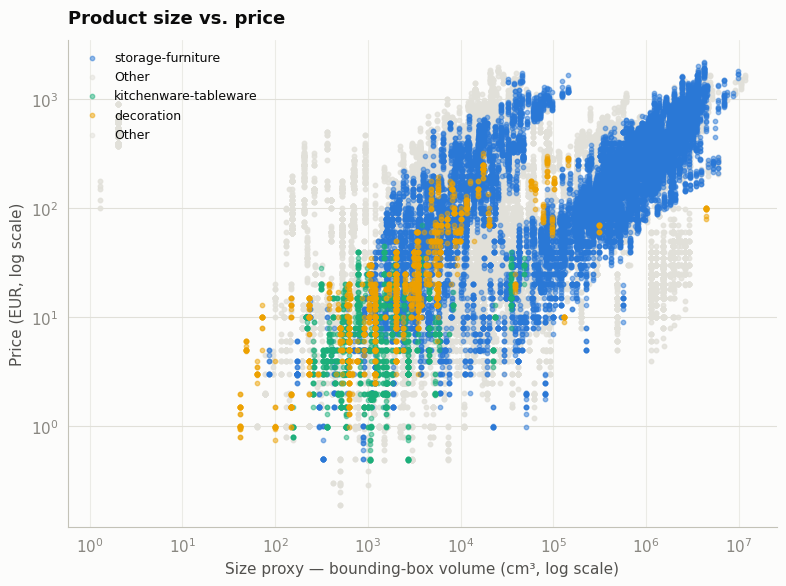

In [19]:
# Size vs. price — top-4 categories coloured, everything else grey 'Other' (keeps the
# scatter within the categorical palette's validated all-pairs cap of 3-4 series)
top4 = df_clean['category_grouped'].value_counts().nlargest(4).index
plot_df = df_clean.dropna(subset=['size_cm3']).copy()
plot_df['color_group'] = plot_df['category_grouped'].where(plot_df['category_grouped'].isin(top4), 'Other')

fig, ax = plt.subplots(figsize=(8, 6))
for i, grp in enumerate(list(top4) + ['Other']):
    sub = plot_df[plot_df['color_group'] == grp]
    color = CAT_COLORS[i] if grp != 'Other' else GRIDLINE
    zorder = 3 if grp != 'Other' else 1
    ax.scatter(sub['size_cm3'], sub['price'], s=10, alpha=0.5, color=color, label=grp, zorder=zorder)

ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Size proxy — bounding-box volume (cm³, log scale)')
ax.set_ylabel('Price (EUR, log scale)')
style_ax(ax, 'Product size vs. price')
ax.legend(frameon=False, fontsize=9, loc='upper left')
plt.tight_layout()
plt.savefig('fig5_size_vs_price.png', dpi=150, bbox_inches='tight')
plt.show()


## 10. Feature engineering

Rather than hand-impute missing values before the train/test split (which risks leaking
information from the test set into the training set's medians), imputation is built into an
sklearn `Pipeline`/`ColumnTransformer` so it is fit on the training fold only and then applied
unchanged to the test fold — the standard, defensible way to do this.

`product_type_en` (3,192 distinct values even after English-referencing) is excluded from the
model features — too high-cardinality to one-hot encode sensibly, and `category_grouped`
already captures the same information at a usable resolution. It stays in the dataset for
reporting and lookup purposes.

**Target:** `log1p(price)`, per the EDA above. **Numeric features:** `size_cm3`,
`product_rating`, `product_rating_count`, `n_dims`, `has_rating`, `online_sellable`.
**Categorical features:** `category_grouped`, `country`, `badge`, `sale_tag`.

In [20]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

NUMERIC_FEATURES = ['size_cm3', 'product_rating', 'product_rating_count', 'n_dims', 'has_rating', 'online_sellable']
CATEGORICAL_FEATURES = ['category_grouped', 'country', 'badge', 'sale_tag']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

model_df = df_clean.copy()
model_df['has_rating'] = model_df['has_rating'].astype(int)
model_df['online_sellable'] = model_df['online_sellable'].astype(int)
model_df['log_price'] = np.log1p(model_df['price'])

X = model_df[FEATURES]
y_log = model_df['log_price']
y_raw = model_df['price']  # kept alongside for reporting error metrics in real euros

X_train, X_test, y_train_log, y_test_log, y_train_raw, y_test_raw = train_test_split(
    X, y_log, y_raw, test_size=0.2, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, ' Test:', X_test.shape)

preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]), NUMERIC_FEATURES),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CATEGORICAL_FEATURES),
    # sparse_output=False: with only ~44 columns after encoding, a dense array is tiny, and
    # RandomForestRegressor is dramatically faster fitting on dense input than on a sparse matrix.
])


Train: (84536, 10)  Test: (21135, 10)


## 11. Train and evaluate the three models

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=300, max_depth=None, random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost': XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=RANDOM_STATE, n_jobs=-1),
}

results = []
fitted_pipelines = {}
predictions = {}

for name, model in models.items():
    pipe = Pipeline([('preprocess', preprocessor), ('model', model)])
    pipe.fit(X_train, y_train_log)
    fitted_pipelines[name] = pipe

    pred_log = pipe.predict(X_test)
    pred_price = np.expm1(pred_log)                              # back-transform to real euros
    # A price can't be negative, and — more importantly for Linear Regression below — a model
    # fit on log(price) can extrapolate to a log-value that explodes once exponentiated. Capping
    # predictions at the highest price actually observed in training keeps that explosion from
    # dominating the error metrics; see the note after this cell for what happens without it.
    pred_price = np.clip(pred_price, 0, y_train_raw.max())
    predictions[name] = pred_price

    rmse = mean_squared_error(y_test_raw, pred_price) ** 0.5
    mae = mean_absolute_error(y_test_raw, pred_price)
    r2 = r2_score(y_test_raw, pred_price)
    r2_log = r2_score(y_test_log, pred_log)

    results.append({'Model': name, 'RMSE (EUR)': rmse, 'MAE (EUR)': mae, 'R2 (price)': r2, 'R2 (log price)': r2_log})

model_results = pd.DataFrame(results).sort_values('RMSE (EUR)')
model_results


,Model,RMSE (EUR),MAE (EUR),R2 (price),R2 (log price)
1,Random Forest,150.013961,46.878116,0.642787,0.832212
2,XGBoost,175.140364,66.181464,0.513104,0.754418
0,Linear Regression,230.506803,92.633547,0.156604,0.517014


**A genuine limitation worth reporting, not hiding:** before the prediction cap above was
added, Linear Regression's back-transformed test-set RMSE was **€2,050** with an **R² of -65.7**
on the raw price scale — worse than just predicting the mean every time. Tracing it: Linear
Regression fits `log1p(price)` reasonably well (log-scale R² ≈ 0.52), but a handful of test
products got a predicted `log_price` around 11.6-11.8, which `expm1()` turns into predicted
prices of **€110,000-€127,000** for items that actually cost around €1,400-€1,800. Random Forest
and XGBoost never do this, because a tree's prediction is the average of training-set values in
a leaf — it is *structurally incapable* of predicting outside the range of prices it saw during
training. A linear model has no such ceiling: it extrapolates in a straight line on the log
scale, and that straight line turns into an exponential explosion once it's un-logged. This is
exactly the kind of failure mode worth naming in the report's implications/limitations
section — it's a reason to prefer log-scale R² when comparing a linear model to tree ensembles,
and a reason a production pricing tool would need a sanity ceiling on any model's output, not
just Linear Regression's.

In [22]:
model_results.to_csv('model_results.csv', index=False)
print('Saved model_results.csv')
model_results


Saved model_results.csv


,Model,RMSE (EUR),MAE (EUR),R2 (price),R2 (log price)
1,Random Forest,150.013961,46.878116,0.642787,0.832212
2,XGBoost,175.140364,66.181464,0.513104,0.754418
0,Linear Regression,230.506803,92.633547,0.156604,0.517014


## 12. Feature importance

Random Forest and XGBoost expose built-in importances; Linear Regression's standardized
coefficients are shown the same way (largest absolute effect first) so all three can be read
side by side.

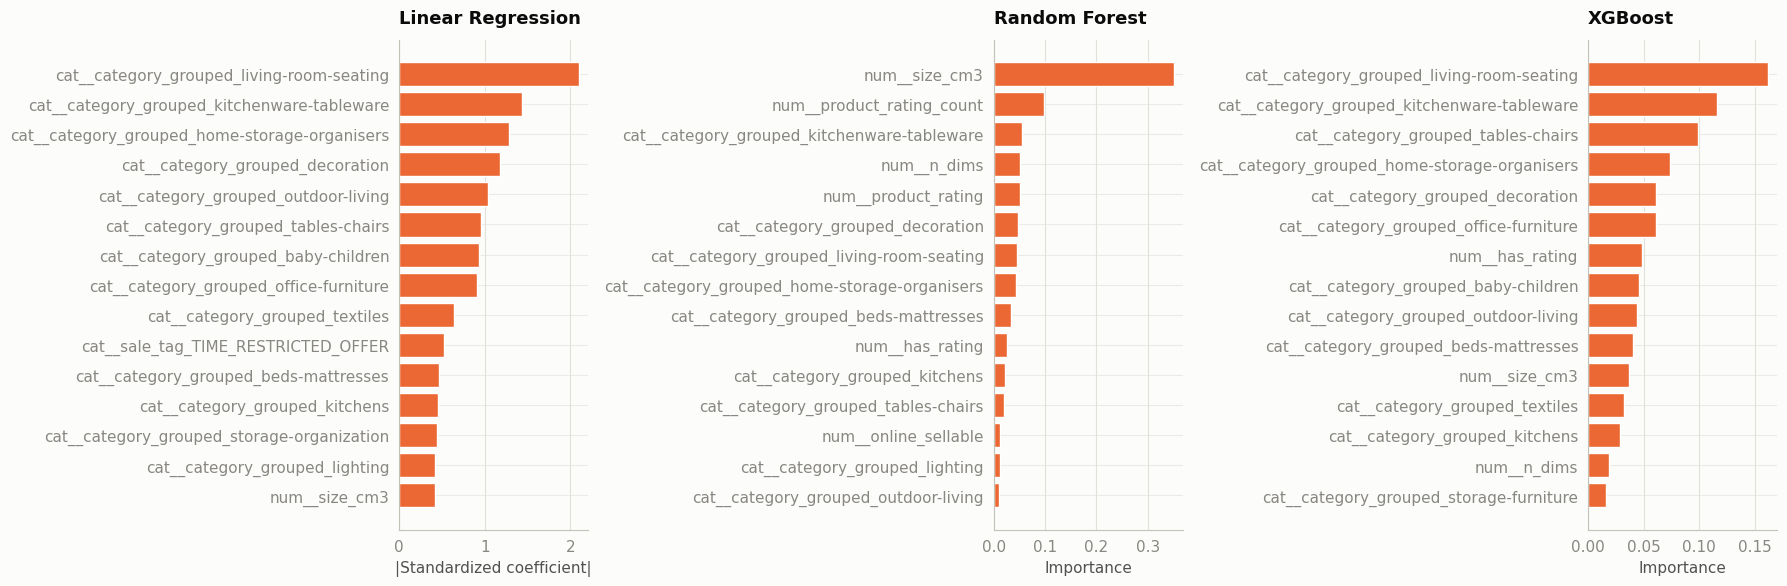

Saved feature_importance.csv


In [23]:
feature_names = fitted_pipelines['Random Forest'].named_steps['preprocess'].get_feature_names_out()

def top_importances(pipe, name, n=15):
    model = pipe.named_steps['model']
    if hasattr(model, 'feature_importances_'):
        vals = model.feature_importances_
    else:
        vals = np.abs(model.coef_)  # Linear Regression: standardized |coefficient|
    imp = pd.Series(vals, index=feature_names).sort_values(ascending=False).head(n)
    return imp

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
importance_records = []
for ax, (name, pipe) in zip(axes, fitted_pipelines.items()):
    imp = top_importances(pipe, name)
    ax.barh(imp.index[::-1], imp.values[::-1], color=CAT_COLORS[1])
    style_ax(ax, name)
    ax.set_xlabel('Importance' if name != 'Linear Regression' else '|Standardized coefficient|')
    for feat, val in imp.items():
        importance_records.append({'model': name, 'feature': feat, 'importance': val})

plt.tight_layout()
plt.savefig('fig6_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

feature_importance = pd.DataFrame(importance_records)
feature_importance.to_csv('feature_importance.csv', index=False)
print('Saved feature_importance.csv')


## 13. Export tables for Power BI

Rather than one wide CSV, this exports a small star-schema-style set of tables — one fact table
plus two dimension tables — so Power BI can slice by category or country without re-deriving
anything, and so the dashboard can directly serve the original business goal from Section 1:
spotting products whose price looks out of line with similar items. That's what `residual` and
`abs_pct_error` are for below — every row is scored with the best-performing model
(Random Forest) and compared against its actual price.

The fact table also carries the product attributes that went into the model
(`size_cm3`, `product_rating`, `badge`, `sale_tag`, `online_sellable`, `measure_unit`) so the
dashboard can filter or group by them directly — e.g. a badge slicer for `TOP_SELLER` products,
or a rating-vs-price view — without joining back to the raw catalog.

In [24]:
# Score every EUR row with the best model to build the Power BI fact table
best_model_name = model_results.iloc[0]['Model']
best_pipe = fitted_pipelines[best_model_name]
print('Best model for Power BI export:', best_model_name)

all_pred_log = best_pipe.predict(X)
all_pred_price = np.clip(np.expm1(all_pred_log), 0, y_train_raw.max())

fact_price = model_df[['unique_id', 'product_id', 'product_name', 'product_type_en',
                        'category_grouped', 'country', 'price',
                        'size_cm3', 'measure_unit', 'n_dims',
                        'product_rating', 'has_rating', 'product_rating_count',
                        'badge', 'sale_tag', 'online_sellable']].copy()
fact_price['predicted_price'] = all_pred_price.round(2)
fact_price['residual'] = (fact_price['price'] - fact_price['predicted_price']).round(2)
fact_price['abs_pct_error'] = (fact_price['residual'].abs() / fact_price['price']).replace([np.inf, -np.inf], np.nan)
fact_price['split'] = np.where(fact_price.index.isin(X_train.index), 'train', 'test')
fact_price['has_rating'] = fact_price['has_rating'].astype(bool)
fact_price['online_sellable'] = fact_price['online_sellable'].astype(bool)

fact_price.to_csv('fact_price.csv', index=False)
print('Saved fact_price.csv —', fact_price.shape)
print()
print('Products with the largest pricing anomaly (actual vs. model-expected price):')
fact_price.reindex(fact_price['abs_pct_error'].sort_values(ascending=False).index).head(10)


Best model for Power BI export: Random Forest


Saved fact_price.csv — (105671, 20)

Products with the largest pricing anomaly (actual vs. model-expected price):


,unique_id,product_id,product_name,product_type_en,category_grouped,country,price,size_cm3,measure_unit,n_dims,product_rating,has_rating,product_rating_count,badge,sale_tag,online_sellable,predicted_price,residual,abs_pct_error,split
85647,80573226-Ireland,80573226,TRIXIG,Stick-on floor protectors set of 20,Other,Ireland,0.50,NaN,missing,0,NaN,False,NaN,NONE,NONE,True,130.47,-129.97,259.940000,train
65848,60615086-Netherlands,60615086,GRILLTIDER,Serving basket,outdoor-living,Netherlands,0.99,NaN,missing,0,NaN,False,NaN,NONE,NEW_PRODUCT,True,230.62,-229.63,231.949495,train
85649,80573226-Netherlands,80573226,TRIXIG,Stick-on floor protectors set of 20,Other,Netherlands,0.49,NaN,missing,0,2.0,True,3.0,NONE,NONE,True,100.48,-99.99,204.061224,test
85651,80573226-Slovakia,80573226,TRIXIG,Stick-on floor protectors set of 20,Other,Slovakia,0.49,NaN,missing,0,NaN,False,NaN,NONE,NONE,True,88.47,-87.98,179.551020,train
17909,20605131-Italy,20605131,PÅLYCKE,Clip-on hook rack,kitchens,Italy,1.95,NaN,missing,0,NaN,False,NaN,NONE,NEW_PRODUCT,True,346.70,-344.75,176.794872,train
49748,50581548-Germany,50581548,BROFJÄRDEN,Soap dish,Other,Germany,7.99,NaN,missing,0,NaN,False,NaN,NONE,NONE,True,796.74,-788.75,98.717146,test
65840,60615086-Austria,60615086,GRILLTIDER,Serving basket,outdoor-living,Austria,1.99,NaN,missing,0,NaN,False,NaN,NONE,NEW_PRODUCT,True,180.99,-179.00,89.949749,train
16069,20573168-Ireland,20573168,TRIXIG,Floor protectors with rivet,Other,Ireland,1.50,NaN,missing,0,NaN,False,NaN,NONE,NONE,True,130.47,-128.97,85.980000,test
59142,60219897-Ireland,60219897,BETYDLIG,Curtain rod holder,Other,Ireland,1.50,NaN,missing,0,NaN,False,NaN,NONE,NONE,True,130.47,-128.97,85.980000,train
37751,40573209-Austria,40573209,BEGRIPA,Handle,kitchens,Austria,5.00,NaN,mm,1,3.5,True,4.0,NONE,NONE,True,434.04,-429.04,85.808000,test


In [25]:
dim_category = (
    model_df.groupby('category_grouped')
    .agg(product_count=('unique_id', 'count'), mean_price=('price', 'mean'), median_price=('price', 'median'))
    .reset_index().sort_values('mean_price', ascending=False)
)
dim_category.to_csv('dim_category.csv', index=False)

dim_country = (
    model_df.groupby('country')
    .agg(product_count=('unique_id', 'count'), mean_price=('price', 'mean'))
    .reset_index().sort_values('mean_price', ascending=False)
)
dim_country.to_csv('dim_country.csv', index=False)

print('Saved dim_category.csv —', dim_category.shape)
print('Saved dim_country.csv —', dim_country.shape)
print()
print(dim_category)


Saved dim_category.csv — (16, 4)
Saved dim_country.csv — (13, 3)

              category_grouped  product_count  mean_price  median_price
9          living-room-seating           2705  577.328484        340.00
13        storage-organization           2778  339.951854        257.24
11              outdoor-living           3096  251.227264        129.00
12           storage-furniture          21945  204.445105        110.00
6                     kitchens           8116  186.934807         74.25
14               tables-chairs           6906  165.348782         99.00
0                        Other          13427  155.023755         29.99
10            office-furniture           2395  153.529854        129.00
2   bathroom-furniture-storage           2205  125.760717         79.98
3              beds-mattresses           6330   78.463177         19.99
15                    textiles           3193   41.342690         14.99
8                     lighting           5573   27.695320         19.9

**Power BI import summary** — five CSVs, ready to load as-is:

| File | Grain | Use in Power BI |
|---|---|---|
| `fact_price.csv` | one row per product × Eurozone market | actual vs. predicted price, residual/anomaly analysis, category/country/badge/rating slicers |
| `dim_category.csv` | one row per category | category-level price summary, joins to `fact_price.category_grouped` |
| `dim_country.csv` | one row per country | country-level price summary, joins to `fact_price.country` |
| `model_results.csv` | one row per model | model comparison table/chart |
| `feature_importance.csv` | one row per model × feature | feature-importance chart, filterable by model |